# Exploratory Data Analysis — Steam Game Reviews

Initial exploration of the raw dataset to understand its structure,
quality, and characteristics before preprocessing.

In [3]:
import sys
from pathlib import Path

# Add project root to path so we can import from src/ and config
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config import REVIEWS_RAW, GAMES_DESC, TARGET_COL, TEXT_COL

# Display settings
pd.set_option("display.max_colwidth", 200)
sns.set_style("whitegrid")

## 1. Load and inspect the raw data

In [4]:
df = pd.read_csv(REVIEWS_RAW)
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"\nColumn types:\n{df.dtypes}")
df.head()

Dataset shape: 10000 rows, 8 columns

Column types:
review            str
hours_played      str
helpful           str
funny             str
recommendation    str
date              str
game_name         str
username          str
dtype: object


,review,hours_played,helpful,funny,recommendation,date,game_name,username
0,2021 Early Access Review The most satisfying game ever. If it had feet it could step on me,36.2,1,0,Recommended,"December 22, 2021",PowerWash Simulator,AAR0N2926\n80 products in account
1,Early Access Review I played 18 hours in the last 2 days and I'm still addicted. SEND HELP!,58.3,2,1,Recommended,August 12,Fields of Mistria,Murasen\n147 products in account
2,The most fun way to develop a gambling addiction.,10.4,1,0,Recommended,March 16,Balatro,Goldoni
3,2022 Amazing game for practising FPV .,77.6,0,0,Recommended,"July 23, 2022",Liftoff®: FPV Drone Racing,Ethan FPV
4,2023 best resident evil ever made,27.0,3,0,Recommended,"March 24, 2023",Resident Evil 4,solid466king


In [5]:
# Missing values per column
print("Missing values:")
print(df.isnull().sum())
print(f"\nTotal rows with at least one missing value: {df.isnull().any(axis=1).sum()}")

Missing values:
review            7
hours_played      0
helpful           0
funny             0
recommendation    0
date              0
game_name         0
username          1
dtype: int64

Total rows with at least one missing value: 8


In [6]:
# Check for duplicate reviews
dupes = df.duplicated(subset=[TEXT_COL], keep=False)
print(f"Duplicate reviews: {dupes.sum()}")
print(f"Unique duplicate texts: {df[dupes][TEXT_COL].nunique()}")

# Show a few examples
if dupes.any():
    print("\nExample duplicates:")
    example = df[dupes].groupby(TEXT_COL).size().sort_values(ascending=False).head()
    print(example)

Duplicate reviews: 296
Unique duplicate texts: 98

Example duplicates:
review
good         15
2023 good    10
2021 good     7
2023 yes      7
2020 yes      7
dtype: int64


Class distribution:
  Recommended: 8122 (81.2%)
  Not Recommended: 1878 (18.8%)


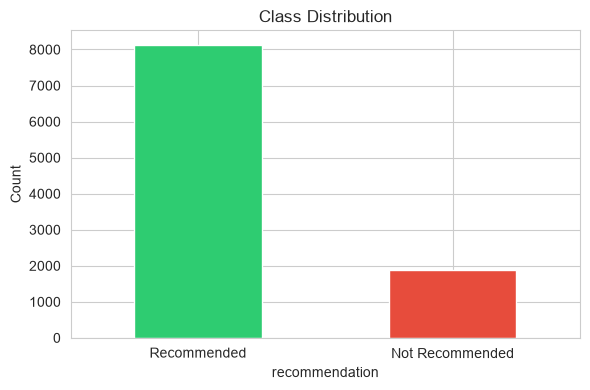

In [9]:
# Class distribution
class_counts = df[TARGET_COL].value_counts()
class_pct = df[TARGET_COL].value_counts(normalize=True) * 100

print("Class distribution:")
for label in class_counts.index:
    print(f"  {label}: {class_counts[label]} ({class_pct[label]:.1f}%)")

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", color=["#2ecc71", "#e74c3c"], ax=ax)
ax.set_title("Class Distribution")
ax.set_ylabel("Count")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

Review length stats:
  Min:    0
  Max:    8157
  Mean:   406
  Median: 108
  Reviews under 10 chars: 490


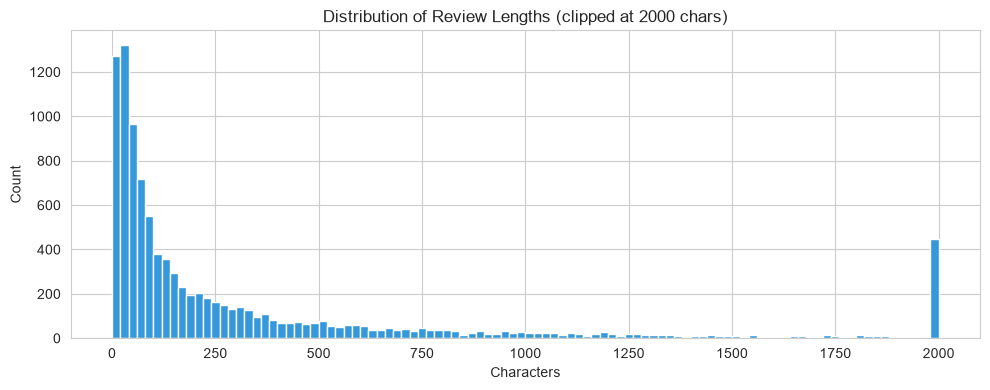

In [10]:
# Review length distribution
df["review_length"] = df[TEXT_COL].fillna("").str.len()

print(f"Review length stats:")
print(f"  Min:    {df['review_length'].min()}")
print(f"  Max:    {df['review_length'].max()}")
print(f"  Mean:   {df['review_length'].mean():.0f}")
print(f"  Median: {df['review_length'].median():.0f}")
print(f"  Reviews under 10 chars: {(df['review_length'] < 10).sum()}")

fig, ax = plt.subplots(figsize=(10, 4))
df["review_length"].clip(upper=2000).hist(bins=100, ax=ax, color="#3498db", edgecolor="white")
ax.set_title("Distribution of Review Lengths (clipped at 2000 chars)")
ax.set_xlabel("Characters")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [11]:
# Reviews per game
reviews_per_game = df["game_name"].value_counts()

print(f"Total unique games: {reviews_per_game.shape[0]}")
print(f"\nReviews per game stats:")
print(f"  Min:    {reviews_per_game.min()}")
print(f"  Max:    {reviews_per_game.max()}")
print(f"  Mean:   {reviews_per_game.mean():.0f}")
print(f"  Median: {reviews_per_game.median():.0f}")

print(f"\nTop 10 games by review count:")
print(reviews_per_game.head(10))

Total unique games: 240

Reviews per game stats:
  Min:    1
  Max:    69
  Mean:   42
  Median: 47

Top 10 games by review count:
game_name
Age of Wonders 4                   69
Fallout 76                         66
Northgard                          66
Balatro                            65
Project Zomboid                    65
Stardew Valley                     64
Need for Speed™ Unbound            64
Plants vs. Zombies GOTY Edition    64
Don't Starve Together              63
Warframe                           63
Name: count, dtype: int64


In [12]:
# Sample reviews to understand text quality
print("=== Short reviews (under 20 chars) ===")
short = df[df["review_length"] < 20][TEXT_COL].head(10)
for i, r in enumerate(short):
    print(f"  {i+1}. '{r}'")

print("\n=== Long reviews (over 3000 chars) — first 200 chars ===")
long_reviews = df[df["review_length"] > 3000][TEXT_COL].head(3)
for i, r in enumerate(long_reviews):
    print(f"  {i+1}. '{r[:200]}...'")

print("\n=== Random sample of medium reviews ===")
medium = df[(df["review_length"] > 50) & (df["review_length"] < 300)][TEXT_COL].sample(5, random_state=42)
for i, r in enumerate(medium):
    print(f"  {i+1}. '{r}'")

=== Short reviews (under 20 chars) ===
  1. '2021 Amazing'
  2. '2023 great'
  3. 'team wahoo'
  4. '2021 skmetbnord'
  5. '2021 nice'
  6. 'monke'
  7. '2023 Very good game'
  8. '2021 very good'
  9. '2023 fat'
  10. '2023 :)'

=== Long reviews (over 3000 chars) — first 200 chars ===
  1. '2020 This game is very...... interesting,At first I thought this game was going a crock of garbage, given how when the game first came out, it was quite fitting of that description. But now, after two...'
  2. '2022 Konami Played Pot Of Greed Konami is doing what Konami knows best, taking a fantastic game and running it into the ground so that they can milk the absolute hell out of it.As I said, the game is ...'
  3. '2016 I'm going to give an introduction to people who have no idea what Garry's mod is and why it's one o the most popular games available on steam. Garry's Mod isn't necessarily a game, it's a tool, i...'

=== Random sample of medium reviews ===
  1. '2021 The combat system is this ga

In [13]:
# Quick check for non-English content patterns
# Instead of using langdetect (slow), check for common non-Latin characters
import re

non_latin = df[TEXT_COL].fillna("").apply(lambda x: bool(re.search(r'[^\x00-\x7F]{5,}', x)))
print(f"Reviews with significant non-Latin characters: {non_latin.sum()}")

# Show examples
if non_latin.any():
    examples = df[non_latin][TEXT_COL].head(5)
    for i, r in enumerate(examples):
        print(f"\n  {i+1}. '{r[:150]}'")

Reviews with significant non-Latin characters: 376

  1. '2016 hoyl freaking heck you can play as freakign EPIC BARON STERNBURG IN KAISERREICH MOD and GENGHIS KHAN 2 why do the paradox try to remove fun ♥♥♥♥♥'

  2. '2023 Very ♥♥♥♥ game. Im not sure how they ♥♥♥♥♥♥ this one up all they had to do was make heat again with some improvements.'

  3. '2017 Early Access Review TLDR - I only wish I'd downloaded this earlierI'm a huge RTS fan but have never bought a game in Early Access before, so Nort'

  4. '2022 太晚買了...優秀的作品Too late to buy.Excellent game.'

  5. '2020 ⡴⠑⡄⠀⠀⠀⠀⠀⠀⠀ ⣀⣀⣤⣤⣤⣀⡀⠸⡇⠀⠿⡀⠀⠀⠀⣀⡴⢿⣿⣿⣿⣿⣿⣿⣿⣷⣦⡀⠀⠀⠀⠀⠑⢄⣠⠾⠁⣀⣄⡈⠙⣿⣿⣿⣿⣿⣿⣿⣿⣆⠀⠀⠀⠀⢀⡀⠁⠀⠀⠈⠙⠛⠂⠈⣿⣿⣿⣿⣿⠿⡿⢿⣆⠀⠀⠀⢀⡾⣁⣀⠀⠴⠂⠙⣗⡀⠀⢻⣿⣿⠭⢤⣴⣦⣤⣹⠀⠀⠀⢀⢴⣶⣆⠀⠀⢀⣾⣿⣿⣿⣷⣮⣽⣾⣿⣥⣴⣿⣿⡿⢂⠔⢚⡿⢿⣿⣦⣴⣾⠸⣼⡿⠀⢀'


In [15]:
# Count specific noise patterns
hearts = df[TEXT_COL].fillna("").str.contains("♥").sum()
print(f"Reviews with ♥ (censored profanity): {hearts}")

print(f"Reviews with significant non-Latin chars: {non_latin.sum()}")

# Check for "Early Access Review" prefix
early_access = df[TEXT_COL].fillna("").str.contains("Early Access Review", case=False).sum()
print(f"Reviews with 'Early Access Review' prefix: {early_access}")

# Check for year prefix pattern (review starts with 4-digit year)
year_prefix = df[TEXT_COL].fillna("").str.match(r'^\d{4}\s').sum()
print(f"Reviews starting with a year (e.g. '2021 ...'): {year_prefix}")

Reviews with ♥ (censored profanity): 431
Reviews with significant non-Latin chars: 376
Reviews with 'Early Access Review' prefix: 1660
Reviews starting with a year (e.g. '2021 ...'): 7671


## EDA Summary — Preprocessing decisions

Based on the exploration above, the preprocessing pipeline needs to:

1. **Drop rows** with missing review text (7 rows)
2. **Remove year prefix** from reviews (e.g. "2021 Great game" → "Great game")
3. **Remove "Early Access Review"** prefix (1,660 reviews)
4. **Remove ♥ symbols** (Steam's censored profanity, 431 reviews)
5. **Remove/filter non-English reviews** (376 reviews with heavy non-Latin text)
6. **Remove ASCII art and special unicode** (braille characters etc.)
7. **Standard text cleaning**: lowercase, remove URLs, fix whitespace
8. **Drop very short reviews** (under 10 characters after cleaning)
9. **Handle class imbalance** (81/19 split) via SMOTE or class weights during training